# Visualize and calculate explained variance for real place and HD neurons

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

from pathlib import Path
current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

## Pfeiffer Place Neurons

have more information here about this dataset

In [2]:
# generate rate maps from Pfeiffer data

import os

save_path = current_file_path / f'results/pfeiffer' 
data_path = current_file_path / f'data/pfeiffer'

rats = [1,2,3,4]

RAT_NEURONS = [204, 174, 79, 94]

velocity_filter = 1  # cm/s
smoothing_filter = 1 # for gaussian smoothing
n_loc_bins = 17      # square env n_loc_bins x n_loc_bins total
n_hd_bins = 17


In [3]:
from src.pfeiffer_ratemaps import get_raw_ratemaps

ratemap_paths = []

for rat in rats:
    metadata = get_raw_ratemaps(
        data_path=data_path, 
        save_path=save_path, 
        rat=rat, 
        n_loc_bins=n_loc_bins, 
        n_hd_bins=n_hd_bins, 
        vel_threshold=velocity_filter, 
        smooth_sigma_hd=smoothing_filter, 
        smooth_sigma_xy=smoothing_filter
    )
    ratemap_paths.append(metadata['out_npz'])
    


=== XY×HD Rate Map Builder ===
Data path : /home/mag/variance-analysis/data/pfeiffer/Rat1/Open1
Save path : /home/mag/variance-analysis/results/pfeiffer/Rat1
XY bins   : 17 × 17 | HD bins: 17
tau: 0.120s | vel_th: 1 cm/s | filter_vel: True
Spikes: 1202745 | Excitatory neurons: 204 | Position samples: 68573
Time bins: 18225 covering 2572.002–4759.002s
Binning spikes into rates…


Y bins: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:01<00:00, 11.07it/s]



Saved: /home/mag/variance-analysis/results/pfeiffer/Rat1/raw_ratemap_xyhd_17x17x17.npz
Done in 0.33 min.

=== XY×HD Rate Map Builder ===
Data path : /home/mag/variance-analysis/data/pfeiffer/Rat2/Open1
Save path : /home/mag/variance-analysis/results/pfeiffer/Rat2
XY bins   : 17 × 17 | HD bins: 17
tau: 0.120s | vel_th: 1 cm/s | filter_vel: True
Spikes: 1059560 | Excitatory neurons: 174 | Position samples: 84918
Time bins: 23600 covering 26300.000–29132.000s
Binning spikes into rates…


Y bins: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:01<00:00,  8.93it/s]



Saved: /home/mag/variance-analysis/results/pfeiffer/Rat2/raw_ratemap_xyhd_17x17x17.npz
Done in 0.31 min.

=== XY×HD Rate Map Builder ===
Data path : /home/mag/variance-analysis/data/pfeiffer/Rat3/Open1
Save path : /home/mag/variance-analysis/results/pfeiffer/Rat3
XY bins   : 17 × 17 | HD bins: 17
tau: 0.120s | vel_th: 1 cm/s | filter_vel: True
Spikes: 463793 | Excitatory neurons: 79 | Position samples: 103669
Time bins: 28825 covering 23451.026–26910.026s
Binning spikes into rates…


Y bins: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:02<00:00,  7.51it/s]



Saved: /home/mag/variance-analysis/results/pfeiffer/Rat3/raw_ratemap_xyhd_17x17x17.npz
Done in 0.19 min.

=== XY×HD Rate Map Builder ===
Data path : /home/mag/variance-analysis/data/pfeiffer/Rat4/Open1
Save path : /home/mag/variance-analysis/results/pfeiffer/Rat4
XY bins   : 17 × 17 | HD bins: 17
tau: 0.120s | vel_th: 1 cm/s | filter_vel: True
Spikes: 815008 | Excitatory neurons: 94 | Position samples: 109873
Time bins: 30542 covering 36875.002–40540.042s
Binning spikes into rates…


Y bins: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:02<00:00,  7.41it/s]



Saved: /home/mag/variance-analysis/results/pfeiffer/Rat4/raw_ratemap_xyhd_17x17x17.npz
Done in 0.22 min.


/tmp/ipykernel_1465058/2290906660.py:7: RuntimeWarning: Mean of empty slice
  xy_hd_ratemap = np.nanmean(raw_ratemap[:, :, :, :, neuron], axis=3)
/tmp/ipykernel_1465058/2290906660.py:10: RuntimeWarning: Mean of empty slice
  xy_ratemap = np.nanmean(xy_hd_ratemap, axis=2)


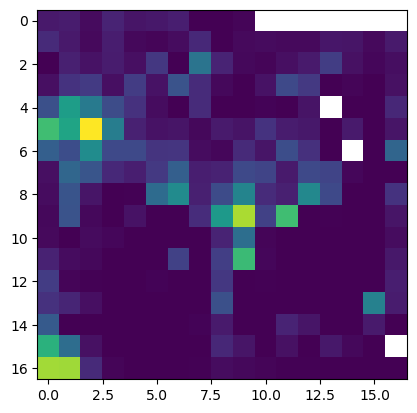

In [16]:
# load rate maps and give option to visualize one

raw_ratemap = np.load(ratemap_paths[0])['rate_map']
y_bins, x_bins, hd_bins, n_visits, n_neurons = raw_ratemap.shape

# first get an average per bin of all the visits
xy_hd_ratemap = np.nanmean(raw_ratemap[:, :, :, :, neuron], axis=3)

# then average over hd to get a set of 2d place rate maps
xy_ratemap = np.nanmean(xy_hd_ratemap, axis=2)

plt.imshow(xy_ratemap)
plt.show()

In [24]:
# load in EV stuff, calculate splits, and summarize EV, then display fig (color coded) 
from src.explained_variance import get_splits, quantify_variance 
from tqdm import tqdm 

rats = [1,2,3,4] 
RAT_NEURONS = [204, 174, 79, 94] 

# some variance seems to come from the train/test split, so average over it 

n_splits = 10 
ev_xy_per_rat = [] 
ev_hd_per_rat = [] 

for r in tqdm(range(len(rats))): 
    raw_ratemap = np.load(ratemap_paths[r])['rate_map'] 
    y, x, hd, visits, neurons = raw_ratemap.shape 
    raw = raw_ratemap.reshape(y * x, hd, visits, neurons) 
    
    ev_xy = np.zeros((RAT_NEURONS[r], n_splits)) 
    ev_hd = np.zeros((RAT_NEURONS[r], n_splits)) 
    
    for n in range(RAT_NEURONS[r]):
        for s in range(n_splits): 
            total_mean, train_mean, test_mean, train_occ, test_occ = get_splits(raw, seed=s) 
            ev_xy[n, s] = quantify_variance(test_mean[:, :, n], train_mean[:, :, n], axis=0, verbose=False)[0]
            ev_hd[n, s] = quantify_variance(test_mean[:, :, n], train_mean[:, :, n], axis=1, verbose=False)[0] 
    ev_xy_per_rat.append(np.nanmean(ev_xy, axis=1)) 
    ev_hd_per_rat.append(np.nanmean(ev_hd, axis=1))



  0%|                                                                                                                                                                                                                       | 0/4 [00:00<?, ?it/s]


KeyError: 0

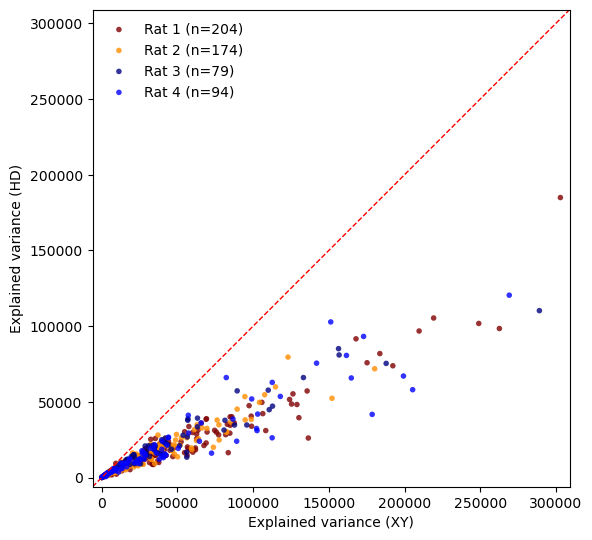

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from matplotlib.colors import Normalize

cmap = get_cmap('jet')
counts = np.array(RAT_NEURONS, dtype=float)
norm = Normalize(vmin=counts.min(), vmax=counts.max())
rat_colors = [cmap(norm(c)) for c in counts]

fig, ax = plt.subplots(figsize=(6, 6))

handles = []
labels = []

for r_idx, r in enumerate(rats):
    x_vals = ev_xy_per_rat[r_idx]
    y_vals = ev_hd_per_rat[r_idx]
    sc = ax.scatter(x_vals, y_vals, s=16, alpha=0.8, edgecolors='none',
                    color=rat_colors[r_idx])
    if len(labels) == r_idx:
        handles.append(sc)
        labels.append(f"Rat {r} (n={RAT_NEURONS[r_idx]})")

# x=y reference line
all_x = np.concatenate(ev_xy_per_rat)
all_y = np.concatenate(ev_hd_per_rat)
lo = float(np.nanmin([all_x.min(), all_y.min()]))
hi = float(np.nanmax([all_x.max(), all_y.max()]))
pad = 0.02 * (hi - lo if hi > lo else 1.0)
lo -= pad
hi += pad
ax.plot([lo, hi], [lo, hi], linestyle='--', linewidth=1.0, color='red')

ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('Explained variance (XY)')
ax.set_ylabel('Explained variance (HD)')
ax.legend(handles, labels, loc='best', frameon=False)


plt.tight_layout()
plt.show()

## Dusz HD Neurons

Duszkiewicz et al 2024

In [5]:
# generate rate maps from Duszkiewicz data

import os

save_path = current_file_path / f'results/dusz' 
data_path = current_file_path / f'data/dusz'

dataset_n = list(range(1,7))


In [6]:
# We only take sessions from square environments for now, so filter by envType

dusz_datasets = {}

from openpyxl import load_workbook
    
wb = load_workbook(data_path / f"Dataset_metadata.xlsx")

for n in dataset_n:
    sheet = wb[f'Dataset_{n}']
        
    dataset_dict = {}
    actual = os.listdir(data_path / f'Dataset_{n}')
    for row in sheet.iter_rows(values_only=True):
        if not row[0] or row[0][0] != 'A':
            continue
        key = row[0]   
        if key not in actual:
            print("Actual dataset missing:", key)
        values = row[3] # environment shapes and neurons
        dataset_dict[key] = values
    dusz_datasets[n] = dataset_dict


Actual dataset missing: A1113-180814


### Plot expected variance for XY vs HD

In [48]:
from src.dusz_ratemaps import get_raw_ratemaps

velocity_filter = 0  # cm/s
n_loc_bins = 10      # square env n_loc_bins x n_loc_bins total
n_hd_bins = 17

In [ ]:
# generate the "raw" (list of visits) ratemaps

ratemap_paths = {}

for n, rats in dusz_datasets.items():
    paths = []
    for rat, env_type in rats.items():
        if env_type != 'Square':
            continue
            
        metadata = get_raw_ratemaps(
            data_path=data_path, 
            save_path=save_path, 
            dataset=n,
            rat=rat, 
            n_loc_bins=n_loc_bins, 
            n_hd_bins=n_hd_bins, 
            vel_threshold=velocity_filter
        )
        paths.append(metadata['out_npz'])
    ratemap_paths[n] = paths

In [54]:
# alternatively, just load it

ratemap_paths = {}

for n in dataset_n:
    paths = {}
    for rat, env_type in dusz_datasets[n].items():
        if env_type != 'Square':
            continue

        paths[rat] = save_path / f'Dataset_{n}/{rat}/raw_rate_xyhd_{n_loc_bins}x{n_loc_bins}x{n_hd_bins}.npz'
    ratemap_paths[n] = paths

/tmp/ipykernel_1154034/2059021529.py:5: RuntimeWarning: Mean of empty slice
  xy_hd_ratemap = np.nanmean(raw_ratemap[:, :, :, :, neuron], axis=3)
/tmp/ipykernel_1154034/2059021529.py:7: RuntimeWarning: Mean of empty slice
  hd_tuning = np.nanmean(xy_hd_ratemap, axis=(0, 1))


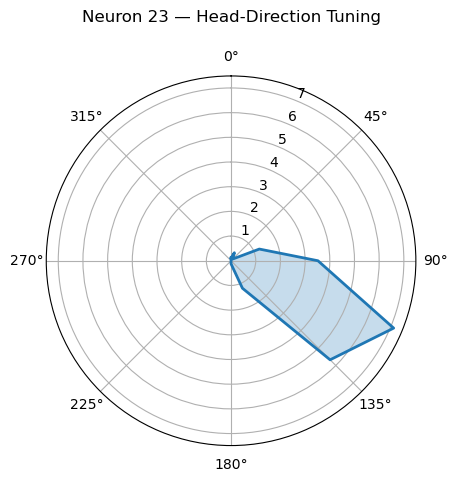

In [55]:
neuron = 23

raw_ratemap = np.load(ratemap_paths[1]['A3701-191119'])['raw_rate_map']

xy_hd_ratemap = np.nanmean(raw_ratemap[:, :, :, :, neuron], axis=3) 

hd_tuning = np.nanmean(xy_hd_ratemap, axis=(0, 1))  
hd_tuning[np.isnan(hd_tuning)] = 0.

theta = np.linspace(0, 2*np.pi, n_hd_bins, endpoint=True)

theta_closed = np.r_[theta, theta[0]]
r_closed = np.r_[hd_tuning, hd_tuning[0]]

fig = plt.figure()
ax = plt.subplot(111, projection='polar')
ax.plot(theta_closed, r_closed, linewidth=2)
ax.fill_between(theta_closed, 0, r_closed, alpha=0.25)

ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)

ax.set_title(f'Neuron {neuron} — Head-Direction Tuning', pad=20)
plt.show()


In [56]:
# load in EV stuff, calculate splits, and summarize EV, then display fig (color coded) 
from src.explained_variance import *
from tqdm import tqdm 
from scipy.ndimage import zoom

# some variance seems to come from the train/test split, so average over it 

sigma = 2. # smoothing
upsample_factor = 2

n_splits = 1
ev_xy_per_rat = [] 
ev_hd_per_rat = [] 

for d in dusz_datasets.keys():
    rats = dusz_datasets[d]
    for r_idx, (r, env_type) in enumerate(rats.items()):
        if env_type != 'Square':
            continue

        raw_ratemap = np.load(ratemap_paths[d][r])['raw_rate_map'] 
        y, x, hd, visits, neurons = raw_ratemap.shape 
        raw = raw_ratemap.reshape(y * x, hd, visits, neurons) 
        
        ev_xy = np.zeros((neurons, n_splits)) 
        ev_hd = np.zeros((neurons, n_splits))
        
        for s in range(n_splits):  
            total_mean, train_mean, test_mean, train_occ, test_occ = get_splits(raw, seed=s)
            for n in tqdm(range(neurons)):  
                test_s = nan_aware_gaussian_filter(test_mean[:, :, n], sigma)
                train_s = nan_aware_gaussian_filter(train_mean[:, :, n], sigma)

                
                global_mean_test = np.nanmean(test_s)
                global_mean_train = np.nanmean(train_s)
                
                total_var_test = np.nansum((test_s - global_mean_test)**2)
                total_var_train = np.nansum((train_s - global_mean_train)**2)
                total_var = 0.5 * (total_var_test + total_var_train)

                xy = quantify_variance(test_s, train_s, axis=0, verbose=False)[0]
                hd = quantify_variance(test_s, train_s, axis=1, verbose=False)[0]
                
                if total_var > 0:
                    ev_xy[n, s] = xy #/ (xy + hd)
                    ev_hd[n, s] = hd #/ (xy + hd)
                else:
                    ev_xy[n, s] = 0
                    ev_hd[n, s] = 0
            
        ev_xy_per_rat.append(np.nanmean(ev_xy, axis=1)) 
        ev_hd_per_rat.append(np.nanmean(ev_hd, axis=1))

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 29/29 [00:00<00:00, 1552.10it/s]


/tmp/ipykernel_1154034/3238623882.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap('jet')


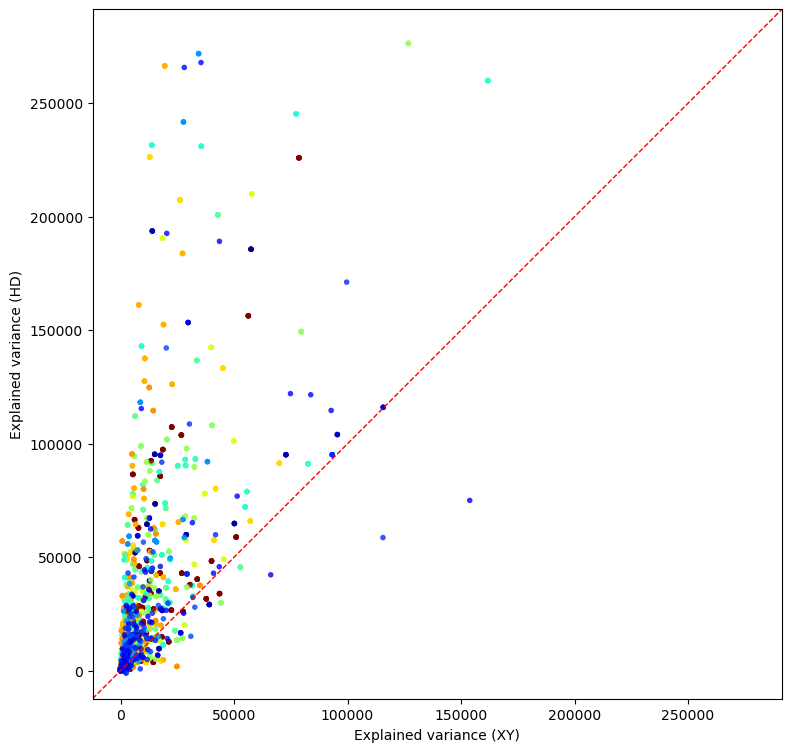

In [58]:
from matplotlib.cm import get_cmap
from matplotlib.colors import Normalize

cmap = get_cmap('jet')
counts = np.array([x.shape[0] for x in ev_xy_per_rat], dtype=float)
norm = Normalize(vmin=counts.min(), vmax=counts.max())
rat_colors = [cmap(norm(c)) for c in counts]

fig, ax = plt.subplots(figsize=(8, 8))

handles = []
labels = []

for n, rats in dusz_datasets.items():
    for r_idx, (r, env_type) in enumerate(rats.items()):
        x_vals = ev_xy_per_rat[r_idx]
        y_vals = ev_hd_per_rat[r_idx]
        sc = ax.scatter(x_vals, y_vals, s=16, alpha=0.8, edgecolors='none',
                        color=rat_colors[r_idx])
        if len(labels) == r_idx:
            handles.append(sc)
            labels.append(f"Rat {r} (n={counts[r_idx]})")

# x=y reference line

all_x = np.concatenate(ev_xy_per_rat)
all_y = np.concatenate(ev_hd_per_rat)
lo = float(np.nanmin([all_x.min(), all_y.min()]))
hi = float(np.nanmax([all_x.max(), all_y.max()]))
pad = 0.02 * (hi - lo if hi > lo else 1.0)
lo -= pad
hi += pad
ax.plot([lo, hi/2], [lo, hi/2], linestyle='--', linewidth=1.0, color='red')

ax.set_xlim(lo, hi/2)
ax.set_ylim(lo, hi/2)


ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('Explained variance (XY)')
ax.set_ylabel('Explained variance (HD)')
#ax.legend(handles, labels, loc='best', frameon=False)


plt.tight_layout()
plt.show()

In [59]:
# this method maybe needs a little bit more hedging against the number of bins in each dimension

### Plot expected variance for MD vs HD

In [7]:
from src.dusz_ratemaps import get_raw_ratemaps

velocity_filter = 1  # cm/s
n_md_bins = 17 
n_hd_bins = 17

In [ ]:
# generate the "raw" (list of visits) ratemaps

ratemap_paths = {}

for n, rats in dusz_datasets.items():
    paths = []
    for rat, env_type in rats.items():
        if env_type != 'Square':
            continue
            
        metadata = get_raw_ratemaps(
            mode='hdmd',
            data_path=data_path, 
            save_path=save_path, 
            dataset=n,
            rat=rat, 
            n_md_bins=n_md_bins, 
            n_hd_bins=n_hd_bins, 
            vel_threshold=velocity_filter, 
        )
        paths.append(metadata['out_npz'])
    ratemap_paths[n] = paths

In [14]:
# alternatively, just load it

ratemap_paths = {}

for n in dataset_n:
    paths = {}
    for rat, env_type in dusz_datasets[n].items():
        if env_type != 'Square':
            continue

        paths[rat] = save_path / f'Dataset_{n}/{rat}/raw_rate_hdmd_{n_hd_bins}x{n_md_bins}.npz'
    ratemap_paths[n] = paths

In [20]:
raw_ratemap.shape

(17, 17, 500, 71)

/tmp/ipykernel_1191990/1554769048.py:5: RuntimeWarning: Mean of empty slice
  hd_md_ratemap = np.nanmean(raw_ratemap[:, :, :, neuron], axis=2)
/tmp/ipykernel_1191990/1554769048.py:7: RuntimeWarning: Mean of empty slice
  hd_tuning = np.nanmean(hd_md_ratemap, axis=(1))


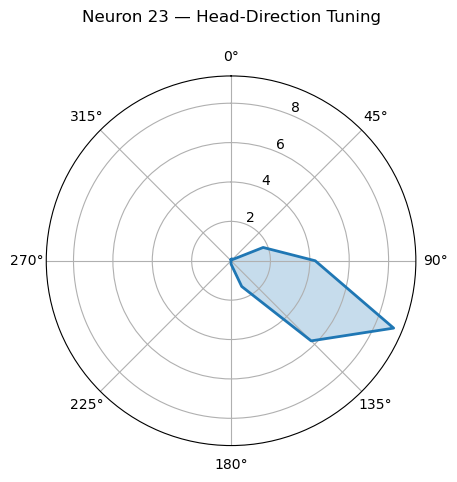

In [25]:
neuron = 23

raw_ratemap = np.load(ratemap_paths[1]['A3701-191119'])['rate_map']

hd_md_ratemap = np.nanmean(raw_ratemap[:, :, :, neuron], axis=2) 

hd_tuning = np.nanmean(hd_md_ratemap, axis=(1))  
hd_tuning[np.isnan(hd_tuning)] = 0.

theta = np.linspace(0, 2*np.pi, n_hd_bins, endpoint=True)

theta_closed = np.r_[theta, theta[0]]
r_closed = np.r_[hd_tuning, hd_tuning[0]]

fig = plt.figure()
ax = plt.subplot(111, projection='polar')
ax.plot(theta_closed, r_closed, linewidth=2)
ax.fill_between(theta_closed, 0, r_closed, alpha=0.25)

ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)

ax.set_title(f'Neuron {neuron} — Head-Direction Tuning', pad=20)
plt.show()


In [29]:
# load in EV stuff, calculate splits, and summarize EV, then display fig (color coded) 
from src.explained_variance import *
from tqdm import tqdm 
from scipy.ndimage import zoom

# some variance seems to come from the train/test split, so average over it 

sigma = 2. # smoothing
upsample_factor = 2

n_splits = 1
ev_md_per_rat = [] 
ev_hd_per_rat = [] 

for d in dusz_datasets.keys():
    rats = dusz_datasets[d]
    for r_idx, (r, env_type) in enumerate(rats.items()):
        if env_type != 'Square':
            continue

        raw_ratemap = np.load(ratemap_paths[d][r])['rate_map'] 
        md, hd, visits, neurons = raw_ratemap.shape 
        raw = raw_ratemap
        
        ev_md = np.zeros((neurons, n_splits)) 
        ev_hd = np.zeros((neurons, n_splits))
        
        for n in tqdm(range(neurons)): 
            for s in range(n_splits): 
                total_mean, train_mean, test_mean, train_occ, test_occ = get_splits(raw, seed=s) 

                test_mean = nan_aware_gaussian_filter(test_mean[:, :, n], sigma)
                train_mean = nan_aware_gaussian_filter(train_mean[:, :, n], sigma)

                test_fine = zoom(test_mean, upsample_factor, order=2)
                train_fine = zoom(train_mean, upsample_factor, order=2)
                
                ev_hd[n, s] = quantify_variance(test_fine, train_fine, axis=0, verbose=False)[0]
                ev_md[n, s] = quantify_variance(test_fine, train_fine, axis=1, verbose=False)[0] 
            
        ev_hd_per_rat.append(np.nanmean(ev_hd, axis=1)) 
        ev_md_per_rat.append(np.nanmean(ev_md, axis=1))

    

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 29/29 [00:07<00:00,  3.71it/s]


/tmp/ipykernel_1191990/898403037.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap('jet')


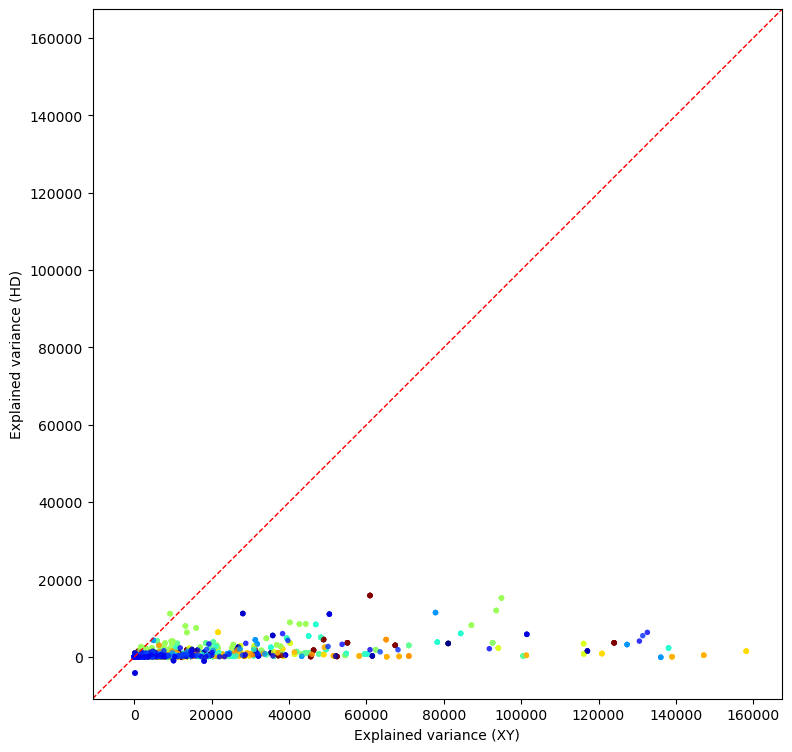

In [28]:
from matplotlib.cm import get_cmap
from matplotlib.colors import Normalize

cmap = get_cmap('jet')
counts = np.array([x.shape[0] for x in ev_md_per_rat], dtype=float)
norm = Normalize(vmin=counts.min(), vmax=counts.max())
rat_colors = [cmap(norm(c)) for c in counts]

fig, ax = plt.subplots(figsize=(8, 8))

handles = []
labels = []

for n, rats in dusz_datasets.items():
    for r_idx, (r, env_type) in enumerate(rats.items()):
        x_vals = ev_md_per_rat[r_idx]
        y_vals = ev_hd_per_rat[r_idx]
        sc = ax.scatter(x_vals, y_vals, s=16, alpha=0.8, edgecolors='none',
                        color=rat_colors[r_idx])
        if len(labels) == r_idx:
            handles.append(sc)
            labels.append(f"Rat {r} (n={counts[r_idx]})")

# x=y reference line
all_x = np.concatenate(ev_md_per_rat)
all_y = np.concatenate(ev_hd_per_rat)
lo = float(np.nanmin([all_x.min(), all_y.min()]))
hi = float(np.nanmax([all_x.max(), all_y.max()]))
pad = 0.02 * (hi - lo if hi > lo else 1.0)
lo -= pad
hi += pad
ax.plot([lo, hi/2], [lo, hi/2], linestyle='--', linewidth=1.0, color='red')

ax.set_xlim(lo, hi/2)
ax.set_ylim(lo, hi/2)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('Explained variance (MD)')
ax.set_ylabel('Explained variance (HD)')
#ax.legend(handles, labels, loc='best', frameon=False)


plt.tight_layout()
plt.show()